# Learning to generate text, one character at a time

A Tiny Shakespeare companion to Lectures 14 and 15

Marcel Turcotte  
2026-11-05

How much of a play could a network learn by predicting its next
character? Spaces, word spellings, speaker labels, and the meaning of a
conversation all operate at different scales. We will train two small
networks and inspect which of these patterns emerge.

This independently executable self-study notebook connects Lecture 14’s
multiclass classification and cross-entropy to Lecture 15’s
one-dimensional convolutions. We first use a feedforward neural network,
then a `Conv1D` network. Both learn from the same text, predict one
character after a fixed context, and use the same generation procedure.

The learning objectives are to construct next-character examples,
explain autoregressive text generation, compare dense and convolutional
processing of a context, and distinguish plausible local text from
sustained coherence.

## Research foundation

<a href="https://www.jmlr.org/papers/v3/bengio03a.html" class="external"
data-icon="true">Bengio, Ducharme, Vincent, and Jauvin (2003)</a>
developed an influential neural probabilistic language model. A
feedforward network receives a fixed number of preceding words and
predicts the next word. The original model jointly learns a shared
vector representation for each word and a prediction network operating
on the concatenated vectors. These learned representations help transfer
information between different word contexts.

We adapt its **fixed-context neural prediction principle**. Our tokens
are characters, our inputs are fixed one-hot vectors, and our hidden
activation is ReLU rather than the paper’s `tanh`. The experiment does
not reproduce its learned word embeddings or its reported results. It
lets us examine the prediction-and-generation mechanism using the layers
already studied.

## Preparation

Run from a fresh kernel, in order. NumPy, Matplotlib, and TensorFlow
with Keras are required. Select the TensorFlow backend before importing
the framework. The default experiment uses the whole corpus and trains
two networks; it takes longer than a short names experiment. Each
training call reports its elapsed time.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
CONTEXT_LENGTH = 32
HIDDEN_UNITS = 128
FILTERS = 64
KERNEL_SIZE = 3
EPOCHS = 12
BATCH_SIZE = 256
LEARNING_RATE = 0.003

keras.utils.set_random_seed(SEED)
print(f"TensorFlow {tf.__version__}; Keras backend: {keras.backend.backend()}")

TensorFlow 2.21.0; Keras backend: tensorflow

## The corpus and its partitions

**Tiny Shakespeare** is a subset of Shakespeare’s works distributed with
Andrej Karpathy’s
<a href="https://github.com/karpathy/char-rnn#data" class="external"
data-icon="true">char-rnn project</a>. It contains approximately 1.1
million characters. Preserve capitalization, punctuation, spaces, and
newlines: each is part of what the network must learn. A period is an
ordinary character, rather than a special instruction to stop.

The course copy is `data/tiny_shakespeare.txt`. If it is absent, Keras
downloads the same corpus into the current directory’s `data` folder. A
fixed source revision and SHA-256 checksum identify the file.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/"
    "6f9487a6fe5b420b7ca9afb0d7c078e37c1d1b4e/data/tinyshakespeare/input.txt"
)
DATA_HASH = "86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed"
data_path = keras.utils.get_file(
    fname="tiny_shakespeare.txt", origin=DATA_URL, file_hash=DATA_HASH,
    cache_dir=".", cache_subdir="data"
)
text = Path(data_path).read_text(encoding="utf-8")
train_end = int(0.8 * len(text))
valid_end = int(0.9 * len(text))
train_text = text[:train_end]
valid_text = text[train_end:valid_end]
test_text = text[valid_end:]

print(f"Corpus: {len(text):,} characters")
print(f"Partitions: {len(train_text):,} training, "
      f"{len(valid_text):,} validation, {len(test_text):,} test")
print("\nBeginning of the training text:\n")
print(train_text[:350])

Corpus: 1,115,394 characters
Partitions: 892,315 training, 111,539 validation, 111,540 test

Beginning of the training text:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
I

We split the continuous text into **contiguous 80%, 10%, and 10% blocks
before constructing windows**. No context or target will cross a
partition boundary. Randomly splitting overlapping windows would place
nearly identical passages in training and evaluation data.

These blocks need not contain the same characters, topics, or speakers
in the same proportions. Evaluation asks how well the model predicts
later held-out text from this compilation; it is not a test on
independent authors or genres. Validation curves are available during
development. The test block is reserved for the final evaluation of the
specified experiment.

## Character IDs and one-hot inputs

A **token** is one unit in a sequence. Here each character is a token,
including spaces and newlines. Build the vocabulary from the training
block and reuse that mapping for validation, test, and generation. In
this particular split, every held-out character also occurs in training.

Character IDs identify categories; their numerical distances have no
meaning. One-hot encoding replaces each ID with a vector containing one
1 and otherwise 0s. This gives one channel per character type, as in the
nucleotide-sequence representation in Lecture 15’s biological-sequence
companion.

In [3]:
vocabulary = sorted(set(train_text))
VOCAB_SIZE = len(vocabulary)
char_to_id = {char: index for index, char in enumerate(vocabulary)}

def encode(passage):
    return np.array([char_to_id[char] for char in passage], dtype="int32")

train_ids = encode(train_text)
valid_ids = encode(valid_text)
test_ids = encode(test_text)

print("Vocabulary size:", VOCAB_SIZE)
print("Characters:", repr("".join(vocabulary)))
print("First twelve IDs:", train_ids[:12])

Vocabulary size: 65
Characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
First twelve IDs: [18 47 56 57 58  1 15 47 58 47 64 43]

## Construct examples one batch at a time

At a starting position $s$, the next-character training example is

$$
\underbrace{c_s,\ldots,c_{s+k-1}}_{\text{context of length }k}
\quad\longrightarrow\quad c_{s+k}.
$$

Sliding the start one character to the right produces another example.
The text supplies its own labels: this is **self-supervised learning**.
Training contexts contain the actual preceding characters from the
corpus.

At the default settings, each input has shape `(32, 65)`, and each
target is one integer ID. Storing every overlapping input as a float32
one-hot array would require several gigabytes. Instead, store the text’s
integer IDs and one starting index per example. Convert only the current
batch to one-hot vectors.

The helper uses a
<a href="https://www.tensorflow.org/guide/data" class="external"
data-icon="true">TensorFlow data pipeline</a>. It batches starting
positions, gathers their contexts and targets, and converts the contexts
to one-hot vectors. `prefetch` prepares upcoming batches while the model
works on the current batch. Shuffling changes the order of complete
examples while preserving character order within every context.

In [4]:
def make_dataset(token_ids, training=False):
    tokens = tf.constant(token_ids)
    starts = tf.data.Dataset.from_tensor_slices(
        np.arange(len(token_ids) - CONTEXT_LENGTH, dtype="int32")
    )
    if training:
        starts = starts.shuffle(len(token_ids) - CONTEXT_LENGTH, seed=SEED)

    def make_batch(start_positions):
        positions = start_positions[:, None] + tf.range(CONTEXT_LENGTH)[None, :]
        contexts = tf.gather(tokens, positions)
        targets = tf.gather(tokens, start_positions + CONTEXT_LENGTH)
        return tf.one_hot(contexts, depth=VOCAB_SIZE), targets

    return starts.batch(BATCH_SIZE).map(
        make_batch, num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)

valid_data = make_dataset(valid_ids)
example_inputs, example_targets = next(iter(make_dataset(train_ids)))
first_context = np.argmax(example_inputs[0].numpy(), axis=-1)
print("First context:", repr("".join(vocabulary[index] for index in first_context)))
print("Next character:", repr(vocabulary[int(example_targets[0])]))
print("Batch inputs:", example_inputs.shape, "Targets:", example_targets.shape)

First context: 'First Citizen:\nBefore we proceed'
Next character: ' '
Batch inputs: (256, 32, 65) Targets: (256,)

The first $k$ characters of each partition provide context but are not
scored as targets. The two models use exactly the same evaluation
targets. There is no beginning-of-text padding token or end-of-name
token in this experiment.

## A feedforward next-character classifier

Flattening the input retains its positions in a fixed-length vector. A
Dense hidden layer with ReLU combines all positions, and the output
layer returns one **logit**, or unnormalized score, per possible next
character.

For target $c_t$ and parameters $\theta$, the loss is

$$
\ell_t = -\log p_\theta(c_t\mid c_{t-k},\ldots,c_{t-1}).
$$

The mean loss $J$ averages over targets. Assigning a greater probability
to the observed next character lowers the loss. Keras accepts integer
target IDs with `SparseCategoricalCrossentropy`. Its `from_logits=True`
option combines the softmax calculation and cross-entropy stably; no
separate softmax layer is needed during training.

In [5]:
mlp = keras.Sequential([
    keras.layers.Input(shape=(CONTEXT_LENGTH, VOCAB_SIZE)),
    keras.layers.Flatten(),
    keras.layers.Dense(HIDDEN_UNITS, activation="relu"),
    keras.layers.Dense(VOCAB_SIZE)
], name="feedforward")

def train_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    )
    start = perf_counter()
    history = model.fit(
        make_dataset(train_ids, training=True), validation_data=valid_data,
        epochs=EPOCHS, verbose=2
    )
    print(f"{model.name}: {model.count_params():,} parameters; "
          f"{perf_counter() - start:.1f} s training")
    return history

## Turn the classifier into a generator

An **autoregressive model** predicts a token using preceding tokens.
Generation samples a character, appends it, and repeats with the updated
context. The weights remain fixed. Unlike training, generation consumes
the model’s own previous predictions, so a poor choice changes the
contexts that follow it.

The prompt must supply at least $k$ characters, all from the training
vocabulary. We use an actual training-text prefix rather than invent
padding that the model has never seen. Once the context is full, only
its final $k$ characters affect the next prediction. Generation always
produces a specified number of new characters; punctuation and newlines
do not stop it.

In [6]:
PROMPT = train_text[:max(64, CONTEXT_LENGTH)]

def next_probabilities(model, prefix, temperature=1.0):
    context = encode(prefix[-CONTEXT_LENGTH:])[None, :]
    inputs = tf.one_hot(context, depth=VOCAB_SIZE)
    logits = model(inputs, training=False)
    probabilities = keras.ops.softmax(logits / temperature, axis=-1)
    return keras.ops.convert_to_numpy(probabilities)[0]

def generate_text(model, prefix, new_characters=400, temperature=0.8, seed=SEED):
    if len(prefix) < CONTEXT_LENGTH:
        raise ValueError("The prompt must contain at least CONTEXT_LENGTH characters.")
    rng = np.random.default_rng(seed)
    passage = prefix
    for _ in range(new_characters):
        probabilities = next_probabilities(model, passage, temperature)
        token = rng.choice(VOCAB_SIZE, p=probabilities)
        passage += vocabulary[token]
    return passage[len(prefix):]

print("Prompt:\n")
print(PROMPT)
print("\nUntrained continuation:\n")
print(generate_text(mlp, PROMPT, new_characters=160))

Prompt:

First Citizen:
Before we proceed any further, hear me speak.

Al

Untrained continuation:

lPqf,xkm.QLuboPBX$obkLysl?R!3dixILS?.RCePogHpmLGe3?
mdglPW3-eRXkbXWF!OANpC$FGdWmeNn: 'gR:T3fOLHbJ'-xtfExlhPF,sQAGY?qjgObZc'N!TJ3,Z;uXJZ xRl'RTvYSEIUO os3W-eFeil

The untrained output is a reference for what learning must accomplish.
Before training, predict which patterns will emerge first: spaces, whole
words, speaker labels, or consistent meaning across sentences.

In [7]:
mlp_history = train_model(mlp)
print("\nFeedforward continuation after training (temperature 0.8):\n")
print(generate_text(mlp, PROMPT))

Epoch 1/12

/Users/turcotte/.virtualenvs/csi4106/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(

3486/3486 - 8s - 2ms/step - loss: 1.9955 - val_loss: 1.9192
Epoch 2/12
3486/3486 - 8s - 2ms/step - loss: 1.7225 - val_loss: 1.8559
Epoch 3/12
3486/3486 - 8s - 2ms/step - loss: 1.6448 - val_loss: 1.8459
Epoch 4/12
3486/3486 - 8s - 2ms/step - loss: 1.6014 - val_loss: 1.8358
Epoch 5/12
3486/3486 - 8s - 2ms/step - loss: 1.5716 - val_loss: 1.8527
Epoch 6/12
3486/3486 - 8s - 2ms/step - loss: 1.5501 - val_loss: 1.8553
Epoch 7/12
3486/3486 - 8s - 2ms/step - loss: 1.5329 - val_loss: 1.8572
Epoch 8/12
3486/3486 - 8s - 2ms/step - loss: 1.5195 - val_loss: 1.8633
Epoch 9/12
3486/3486 - 8s - 2ms/step - loss: 1.5073 - val_loss: 1.8739
Epoch 10/12
3486/3486 - 8s - 2ms/step - loss: 1.4976 - val_loss: 1.8811
Epoch 11/12
3486/3486 - 8s - 2ms/step - loss: 1.4891 - val_loss: 1.8904
Epoch 12/12
3486/3486 - 8s - 2ms/step - loss: 1.4817 - val_loss: 1.8932
feedforward: 274,753 parameters; 91.9 s training

Feedforward continuation after training (temperature 0.8):

l: new, and steat the would beet
Lest Tobsens.

## Inspect one next-character distribution

We can inspect a prediction rather than judging only a complete passage.
Several next characters may be plausible even though an observed example
has only one target. Spaces and newlines have their own probabilities.

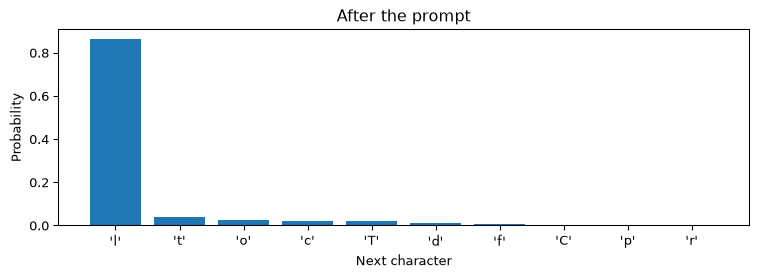

In [8]:
probabilities = next_probabilities(mlp, PROMPT)
top = np.argsort(probabilities)[-10:][::-1]
labels = [repr(vocabulary[index]) for index in top]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(labels, probabilities[top])
ax.set(xlabel="Next character", ylabel="Probability", title="After the prompt")
fig.tight_layout()
plt.show()

## Replace the first transformation with Conv1D

A width-three convolution examines local character triples and reuses
each filter’s weights across positions. With 64 filters and valid
padding, the default `(32, 65)` input becomes a `(30, 64)` feature map.
`Flatten` preserves where each response occurred, and the Dense layer
combines responses across the entire context. Each local convolutional
response sees three characters; the complete predictor can use all 32.

Every input contains only characters preceding its one target. Ordinary
valid convolution therefore exposes no future characters to that
prediction. If we instead predicted at every position of a complete
sequence, we would need causal convolutions or another constraint
preventing each prediction from using later characters. See the
<a href="https://keras.io/api/layers/convolution_layers/convolution1d/"
class="external" data-icon="true">Keras Conv1D documentation</a>.

We use 64 filters to keep the parameter counts close: at the default
settings, 274,753 for the MLP and 266,817 for the CNN. Both receive
twelve full passes over the training examples with the same batch size,
optimizer, and learning rate. Approximate parameter matching does not
guarantee equal computation, expressive capacity, or quality after
tuning.

In [9]:
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    keras.layers.Input(shape=(CONTEXT_LENGTH, VOCAB_SIZE)),
    keras.layers.Conv1D(FILTERS, KERNEL_SIZE, padding="valid", activation="relu"),
    keras.layers.Flatten(),
    keras.layers.Dense(HIDDEN_UNITS, activation="relu"),
    keras.layers.Dense(VOCAB_SIZE)
], name="convolutional")

cnn_history = train_model(cnn)
print("\nConv1D continuation after training (temperature 0.8):\n")
print(generate_text(cnn, PROMPT))

Epoch 1/12
3486/3486 - 15s - 4ms/step - loss: 1.9632 - val_loss: 1.8902
Epoch 2/12
3486/3486 - 15s - 4ms/step - loss: 1.7196 - val_loss: 1.8357
Epoch 3/12
3486/3486 - 15s - 4ms/step - loss: 1.6602 - val_loss: 1.8236
Epoch 4/12
3486/3486 - 15s - 4ms/step - loss: 1.6267 - val_loss: 1.8192
Epoch 5/12
3486/3486 - 15s - 4ms/step - loss: 1.6028 - val_loss: 1.8192
Epoch 6/12
3486/3486 - 15s - 4ms/step - loss: 1.5857 - val_loss: 1.8176
Epoch 7/12
3486/3486 - 15s - 4ms/step - loss: 1.5726 - val_loss: 1.8238
Epoch 8/12
3486/3486 - 15s - 4ms/step - loss: 1.5612 - val_loss: 1.8206
Epoch 9/12
3486/3486 - 15s - 4ms/step - loss: 1.5516 - val_loss: 1.8274
Epoch 10/12
3486/3486 - 15s - 4ms/step - loss: 1.5444 - val_loss: 1.8349
Epoch 11/12
3486/3486 - 15s - 4ms/step - loss: 1.5375 - val_loss: 1.8402
Epoch 12/12
3486/3486 - 15s - 4ms/step - loss: 1.5314 - val_loss: 1.8372
convolutional: 266,817 parameters; 179.3 s training

Conv1D continuation after training (temperature 0.8):

l:
Now, and the marriay. 

## Follow learning on held-out text

The loss measures the probability assigned to observed next characters.
The training curve averages losses while parameters are changing during
an epoch; validation loss is computed afterward with the resulting
parameters. A gap between them can indicate overfitting. Later epochs
need not improve prediction on unseen passages.

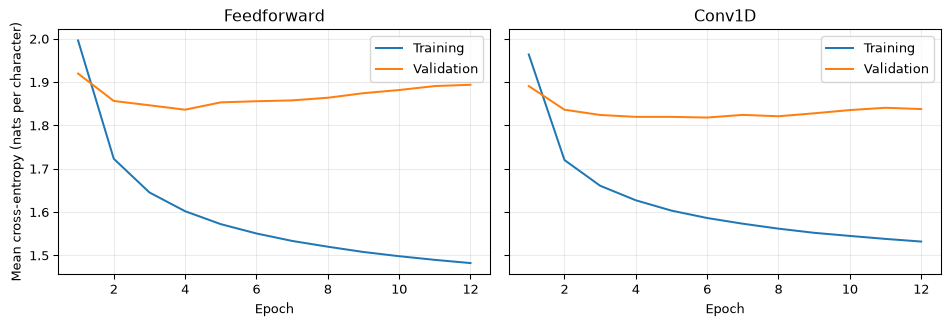

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, history, title in zip(
    axes, (mlp_history, cnn_history), ("Feedforward", "Conv1D")
):
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    ax.plot(epochs, history.history["loss"], label="Training")
    ax.plot(epochs, history.history["val_loss"], label="Validation")
    ax.set(title=title, xlabel="Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Mean cross-entropy (nats per character)")
fig.tight_layout()
plt.show()

## Temperature changes sampling

For temperature $T>0$, probabilities are proportional to $\exp(z_j/T)$,
where $z_j$ is the logit for character $j$. At $T=1$, sampling uses the
learned distribution. Lower temperatures concentrate probability on
high-scoring characters; higher temperatures flatten the distribution.
This changes generation without changing parameters or the training
loss.

The same prompt, generation length, and random seed are used below.
Predict which temperature will produce more repetition and which will
produce more spelling errors, then inspect the actual passages.

In [11]:
for model in (mlp, cnn):
    for temperature in (0.6, 1.0, 1.2):
        print(f"\n{model.name}, temperature {temperature}:\n")
        print(generate_text(model, PROMPT, new_characters=240, temperature=temperature))


feedforward, temperature 0.6:

l: of with whild I shall die thou secreeks grown.

AUTOLYCUS:
I thus nother is the ears an the pights,
Which we have on the and blet'd!
Which with mides, I dream, Marry, if you would her brother esseess a gentleman their ows their horth,
An

feedforward, temperature 1.0:

l: may the with ofher you harry;
For in sun to him Cortain, there of
That I grissera aopeach in halts,
Yound up my tone, sen mon, curse which wis.

GLOUCESTER:
As Clown, a his hust. I shall we there how a desempless.

VIRGILIA:
Thank'st tak

feedforward, temperature 1.2:

l: may the with never you if thy godef-cast, their I prore as not oland!

BENVOLIO:
A mide, king a worlust fauling withang iffecar,' he with my keep,
Will sengt vedless whence my rowans:
And, as I warry'd
Edward conse,!
Distatake aly to tak

convolutional, temperature 0.6:

l:
Now, and the marriast, aboutai.

CLARENCE:
I the too must me? my bidce a griend a concients than, thou knither consents in me shower
hen stripec

## Inspect local form and global coherence separately

When reading samples, distinguish these questions:

- Are spaces, capitalization, punctuation, and line breaks plausible?
- Which words are correctly spelled? Which are invented fragments?
- Do adjacent words form grammatical phrases?
- Do speakers and subjects remain consistent across several sentences?

A convincing speaker label or short phrase can emerge while the
surrounding passage has little meaning. Cross-entropy can improve as the
model learns many local regularities; that does not establish that
generated conversations are coherent. A single appealing sample also
cannot establish which model is better.

## A visible limit on context

The network receives only the final $k$ characters of a prefix. To
isolate that fact, construct two different prefixes with an identical
final context. Print that context and compare the two predicted
distributions **within each model**. This is not a comparison between
the MLP and CNN distributions.

In [12]:
shared_context = PROMPT[-CONTEXT_LENGTH:]
prefix_a = "The king is angry.\n" + shared_context
prefix_b = "The king is pleased.\n" + shared_context
print("Shared visible context:", repr(shared_context))
for model in (mlp, cnn):
    difference = np.max(np.abs(next_probabilities(model, prefix_a)
                               - next_probabilities(model, prefix_b)))
    print(f"{model.name}: largest probability difference = {difference:.1e}")

Shared visible context: ' any further, hear me speak.\n\nAl'
feedforward: largest probability difference = 0.0e+00
convolutional: largest probability difference = 0.0e+00

The difference must be zero: each model receives exactly the same
numeric input in both calls. This demonstrates a hard context limit,
independently of how well the network has learned. It remains true when
we change $k$, because the example constructs a shared suffix of exactly
that length.

## Context-length experiments

The default 32-character context can cover several short words. Compare
it with 8 and 64 characters by changing `CONTEXT_LENGTH`, restarting the
kernel, and rerunning setup, training, sampling, and validation plots.
**Skip the final test-evaluation cell while choosing settings.**

Longer contexts expose additional information, but the network must
learn to use it. They also increase parameter counts in both
architectures. This simple experiment therefore changes both context and
model capacity. Longer context need not yield more coherent samples or
lower validation loss.

Other focused experiments are to vary `KERNEL_SIZE` while keeping it no
larger than the context, or to replace sampling with greedy decoding.
Predict the feature-map shape or change in diversity before running each
experiment.

## Final evaluation: use the test block once

The following cell evaluates the predeclared twelve-epoch models. When
doing the experiments above, leave this cell unexecuted until settings
are settled. Repeatedly choosing settings from test results turns the
test set into another validation set.

For reference, a **bigram model** predicts a character using only its
immediate predecessor. We count adjacent pairs in training text and add
one to every count, giving unseen pairs positive probability. It is
scored on the same test targets as the neural networks.

Cross-entropy is measured in **nats per character**. Dividing it by
$\log 2$ gives **bits per character**; exponentiating it gives
**perplexity**. Lower is better under all three transformations. These
are equivalent views of the same mean loss, rather than three
independent measures. Compare them across models on this corpus, not
directly with scores on a names corpus with a different alphabet and
distribution.

In [13]:
bigram_counts = np.ones((VOCAB_SIZE, VOCAB_SIZE))
np.add.at(bigram_counts, (train_ids[:-1], train_ids[1:]), 1)
bigram_probabilities = bigram_counts / bigram_counts.sum(axis=1, keepdims=True)
previous = test_ids[CONTEXT_LENGTH - 1:-1]
targets = test_ids[CONTEXT_LENGTH:]
bigram_loss = -np.log(bigram_probabilities[previous, targets]).mean()

test_losses = {"Bigram": bigram_loss}
test_data = make_dataset(test_ids)
for label, model in (("Feedforward", mlp), ("Conv1D", cnn)):
    test_losses[label] = model.evaluate(test_data, verbose=0)

print(f"{'Model':<15} {'Nats/character':>16} {'Bits/character':>16} {'Perplexity':>12}")
for label, loss in test_losses.items():
    print(f"{label:<15} {loss:>16.3f} {loss / np.log(2):>16.3f} {np.exp(loss):>12.2f}")

Model             Nats/character   Bits/character   Perplexity
Bigram                     2.503            3.612        12.22
Feedforward                2.348            3.387        10.46
Conv1D                     2.372            3.422        10.72

## Connection to large language models

The central mechanism is shared: tokens form contexts, a network
predicts next-token logits, cross-entropy trains the predictions, and
sampling repeatedly extends a prompt. The learned parameters stay fixed
during ordinary generation.

Our shallow networks learn from a small, narrow corpus and have a short,
fixed context. Modern autoregressive transformer language models use
learned token representations and attention within much larger contexts,
often with subword tokens. Their scale, training data, and subsequent
instruction training support capabilities that this experiment does not
test. Recognizable text structure is evidence of learned patterns; it
does not by itself establish reliable reasoning, factual knowledge, or
instruction following.

## References

- Bengio, Y., Ducharme, R., Vincent, P., and Jauvin, C. (2003).
  <a href="https://www.jmlr.org/papers/v3/bengio03a.html" class="external"
  data-icon="true">A Neural Probabilistic Language Model</a>. *Journal
  of Machine Learning Research*, **3**, 1137–1155. See Section 2 and
  Figure 1 for fixed-context prediction and learned word vectors.
- Shakespeare, W. Text compiled as Tiny Shakespeare in Karpathy, A.,
  <a href="https://github.com/karpathy/char-rnn#data" class="external"
  data-icon="true">char-rnn</a>. The loading cell specifies the exact
  corpus revision and checksum.